In [1]:
# ==========================================================
# STEP 1: INITIALIZE THE ENTERPRISE DATABASE
# ==========================================================

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

# Visual styling
sns.set_style("whitegrid")

# Create a fresh database connection
conn = sqlite3.connect('enterprise_lms.db')
cursor = conn.cursor()

# 1. Create Tables
cursor.execute('''
    CREATE TABLE IF NOT EXISTS students (
        student_id TEXT PRIMARY KEY,
        full_name TEXT,
        email TEXT,
        program TEXT
    )
''')

cursor.execute('''
    CREATE TABLE IF NOT EXISTS courses (
        course_id TEXT PRIMARY KEY,
        course_name TEXT,
        department TEXT
    )
''')

cursor.execute('''
    CREATE TABLE IF NOT EXISTS enrollments (
        enrollment_id INTEGER PRIMARY KEY,
        student_id TEXT,
        course_id TEXT,
        current_grade REAL
    )
''')

cursor.execute('''
    CREATE TABLE IF NOT EXISTS lms_logs (
        log_id INTEGER PRIMARY KEY,
        student_id TEXT,
        action TEXT,
        timestamp TEXT
    )
''')

# 2. Insert Records (Deliberately includes realistic text inconsistencies)
students = [
    ('STU_101', '  Amina Okafor ', 'amina@school.edu', 'Computer Science'),
    ('STU_102', 'JAMES SMITH', 'james@school.edu', 'Data Science'),
    ('STU_103', 'fatima bello', 'fatima@school.edu', 'Computer Science'),
    ('STU_104', 'David Chen', 'david@school.edu', 'Education Tech'),
    ('STU_105', 'Grace Eze', 'grace@school.edu', 'Data Science'),
    ('STU_106', 'Omar Hassan ', 'omar@school.edu', 'Computer Science'),
    ('STU_107', 'Sarah Williams', 'sarah@school.edu', 'Education Tech'),
    ('STU_108', 'Chidi Nwosu', 'chidi@school.edu', 'Data Science'),
    ('STU_109', 'Lena Mueller', 'lena@school.edu', 'Computer Science'),
    ('STU_110', 'Kwame Asante', 'kwame@school.edu', 'Education Tech')
]

courses = [
    ('CS501', 'Learning Analytics Systems', 'Computer Science'),
    ('ED302', 'Instructional Design Foundations', 'Education'),
    ('DS201', 'Database Architectures', 'Data Science')
]

enrollments = [
    (1, 'STU_101', 'CS501', 88.5),
    (2, 'STU_102', 'DS201', 42.0),  # Failing
    (3, 'STU_103', 'CS501', 94.0),  # High performer
    (4, 'STU_104', 'ED302', 78.0),
    (5, 'STU_105', 'DS201', 48.5),  # Failing
    (6, 'STU_106', 'CS501', 62.0),
    (7, 'STU_107', 'ED302', 91.0),  # High performer
    (8, 'STU_108', 'DS201', 73.0),
    (9, 'STU_109', 'CS501', 45.0),  # Failing
    (10, 'STU_110', 'ED302', 82.0)
]

# Clickstream logs across the last 14 days (Sept 1 to Sept 14, 2026)
logs = [
    (1, 'STU_101', 'login', '2026-09-14 09:30:00'), # Active today
    (2, 'STU_102', 'login', '2026-09-02 11:15:00'), # Inactive for 12 days! (Ghost)
    (3, 'STU_103', 'view_lecture', '2026-09-14 14:20:00'), # Active today
    (4, 'STU_104', 'submit_assignment', '2026-09-10 16:00:00'),
    (5, 'STU_105', 'login', '2026-09-04 08:00:00'), # Inactive for 10 days! (Ghost)
    (6, 'STU_106', 'view_lecture', '2026-09-13 19:45:00'),
    (7, 'STU_107', 'submit_assignment', '2026-09-14 10:10:00'),
    (8, 'STU_108', 'login', '2026-09-12 12:00:00'),
    (9, 'STU_109', 'view_lecture', '2026-09-14 08:30:00'), # Low grade, but actively trying
    (10, 'STU_110', 'login', '2026-09-03 14:00:00') # Inactive for 11 days!
]

# Insert cleanly
cursor.executemany('INSERT OR IGNORE INTO students VALUES (?, ?, ?, ?)', students)
cursor.executemany('INSERT OR IGNORE INTO courses VALUES (?, ?, ?)', courses)
cursor.executemany('INSERT OR IGNORE INTO enrollments VALUES (?, ?, ?, ?)', enrollments)
cursor.executemany('INSERT OR IGNORE INTO lms_logs VALUES (?, ?, ?, ?)', logs)
conn.commit()

print("✅ ENTERPRISE DATABASE INITIALIZED & POPULATED!")

✅ ENTERPRISE DATABASE INITIALIZED & POPULATED!


In [4]:
# ==========================================================
# STEP 2: SQL EXTRACTION & DATA SANITIZATION
# ==========================================================

# 1. SQL Query: Join academic records
sql_query = """
    SELECT
    s.student_id,
    s.full_name,
    s.email,
    s.program,
    c.course_id,
    c.course_name,
    c.department,
    e.current_grade

 FROM enrollments e
 JOIN students s ON e.student_id = s.student_id
 JOIN courses c ON e.course_id = c.course_id
 """
df_academic = pd.read_sql_query(sql_query, conn)

# 2. Text Cleaning: Sanitize messy names and emails
df_academic['full_name'] = df_academic['full_name'].str.strip().str.title()
df_academic['email'] = df_academic['email'].str.lower()

# 3. Pull and process latest login timestamp per student from lms_logs
df_logs = pd.read_sql_query("SELECT student_id, timestamp FROM lms_logs", conn)
df_logs['timestamp'] = pd.to_datetime(df_logs['timestamp'])

# Find the MAXIMUM (latest) timestamp for each student
df_latest_login = df_logs.groupby('student_id')['timestamp'].max().reset_index()
df_latest_login.columns = ['student_id', 'last_login']

# 4. Merge academic data with the latest login data
df_unified = pd.merge(df_academic, df_latest_login, on='student_id', how='left')

print("--- SANITIZED UNIFIED STUDENT DATASET ---")
df_unified
    

--- SANITIZED UNIFIED STUDENT DATASET ---


,student_id,full_name,email,program,course_id,course_name,department,current_grade,last_login
0,STU_101,Amina Okafor,amina@school.edu,Computer Science,CS501,Learning Analytics Systems,Computer Science,88.5,2026-09-14 09:30:00
1,STU_102,James Smith,james@school.edu,Data Science,DS201,Database Architectures,Data Science,42.0,2026-09-02 11:15:00
2,STU_103,Fatima Bello,fatima@school.edu,Computer Science,CS501,Learning Analytics Systems,Computer Science,94.0,2026-09-14 14:20:00
3,STU_104,David Chen,david@school.edu,Education Tech,ED302,Instructional Design Foundations,Education,78.0,2026-09-10 16:00:00
4,STU_105,Grace Eze,grace@school.edu,Data Science,DS201,Database Architectures,Data Science,48.5,2026-09-04 08:00:00
5,STU_106,Omar Hassan,omar@school.edu,Computer Science,CS501,Learning Analytics Systems,Computer Science,62.0,2026-09-13 19:45:00
6,STU_107,Sarah Williams,sarah@school.edu,Education Tech,ED302,Instructional Design Foundations,Education,91.0,2026-09-14 10:10:00
7,STU_108,Chidi Nwosu,chidi@school.edu,Data Science,DS201,Database Architectures,Data Science,73.0,2026-09-12 12:00:00
8,STU_109,Lena Mueller,lena@school.edu,Computer Science,CS501,Learning Analytics Systems,Computer Science,45.0,2026-09-14 08:30:00
9,STU_110,Kwame Asante,kwame@school.edu,Education Tech,ED302,Instructional Design Foundations,Education,82.0,2026-09-03 14:00:00


In [8]:
# ==========================================================
# STEP 3: MULTI-FACTOR RISK SCORING ALGORITHM (CLEAN TEXT)
# ==========================================================

# Set current evaluation date (the system's "today")
current_date = pd.to_datetime('2026-09-14 23:59:59')

# Calculate days since last active login
df_unified['days_inactive'] = (current_date - df_unified['last_login']).dt.days

# The Decision Engine Function
def calculate_early_warning_status(row):
    """
    Evaluates both Academic Performance and Behavioral Inactivity.
    Returns a clean, professional status category.
    """
    is_failing = row['current_grade'] < 50.0
    is_inactive = row['days_inactive'] >= 5
    
    if is_failing and is_inactive:
        return 'Critical (Failing + Inactive)'
    elif is_failing and not is_inactive:
        return 'Academic Risk (Failing Grade)'
    elif not is_failing and is_inactive:
        return 'Engagement Risk (Inactive)'
    else:
        return 'Good Standing'

# Apply the logic across all rows
df_unified['risk_level'] = df_unified.apply(calculate_early_warning_status, axis=1)

print("--- EARLY WARNING AUDIT TABLE ---")
df_unified[['student_id', 'full_name', 'course_name', 'current_grade', 'days_inactive', 'risk_level']]

--- EARLY WARNING AUDIT TABLE ---


,student_id,full_name,course_name,current_grade,days_inactive,risk_level
0,STU_101,Amina Okafor,Learning Analytics Systems,88.5,0,Good Standing
1,STU_102,James Smith,Database Architectures,42.0,12,Critical (Failing + Inactive)
2,STU_103,Fatima Bello,Learning Analytics Systems,94.0,0,Good Standing
3,STU_104,David Chen,Instructional Design Foundations,78.0,4,Good Standing
4,STU_105,Grace Eze,Database Architectures,48.5,10,Critical (Failing + Inactive)
5,STU_106,Omar Hassan,Learning Analytics Systems,62.0,1,Good Standing
6,STU_107,Sarah Williams,Instructional Design Foundations,91.0,0,Good Standing
7,STU_108,Chidi Nwosu,Database Architectures,73.0,2,Good Standing
8,STU_109,Lena Mueller,Learning Analytics Systems,45.0,0,Academic Risk (Failing Grade)
9,STU_110,Kwame Asante,Instructional Design Foundations,82.0,11,Engagement Risk (Inactive)


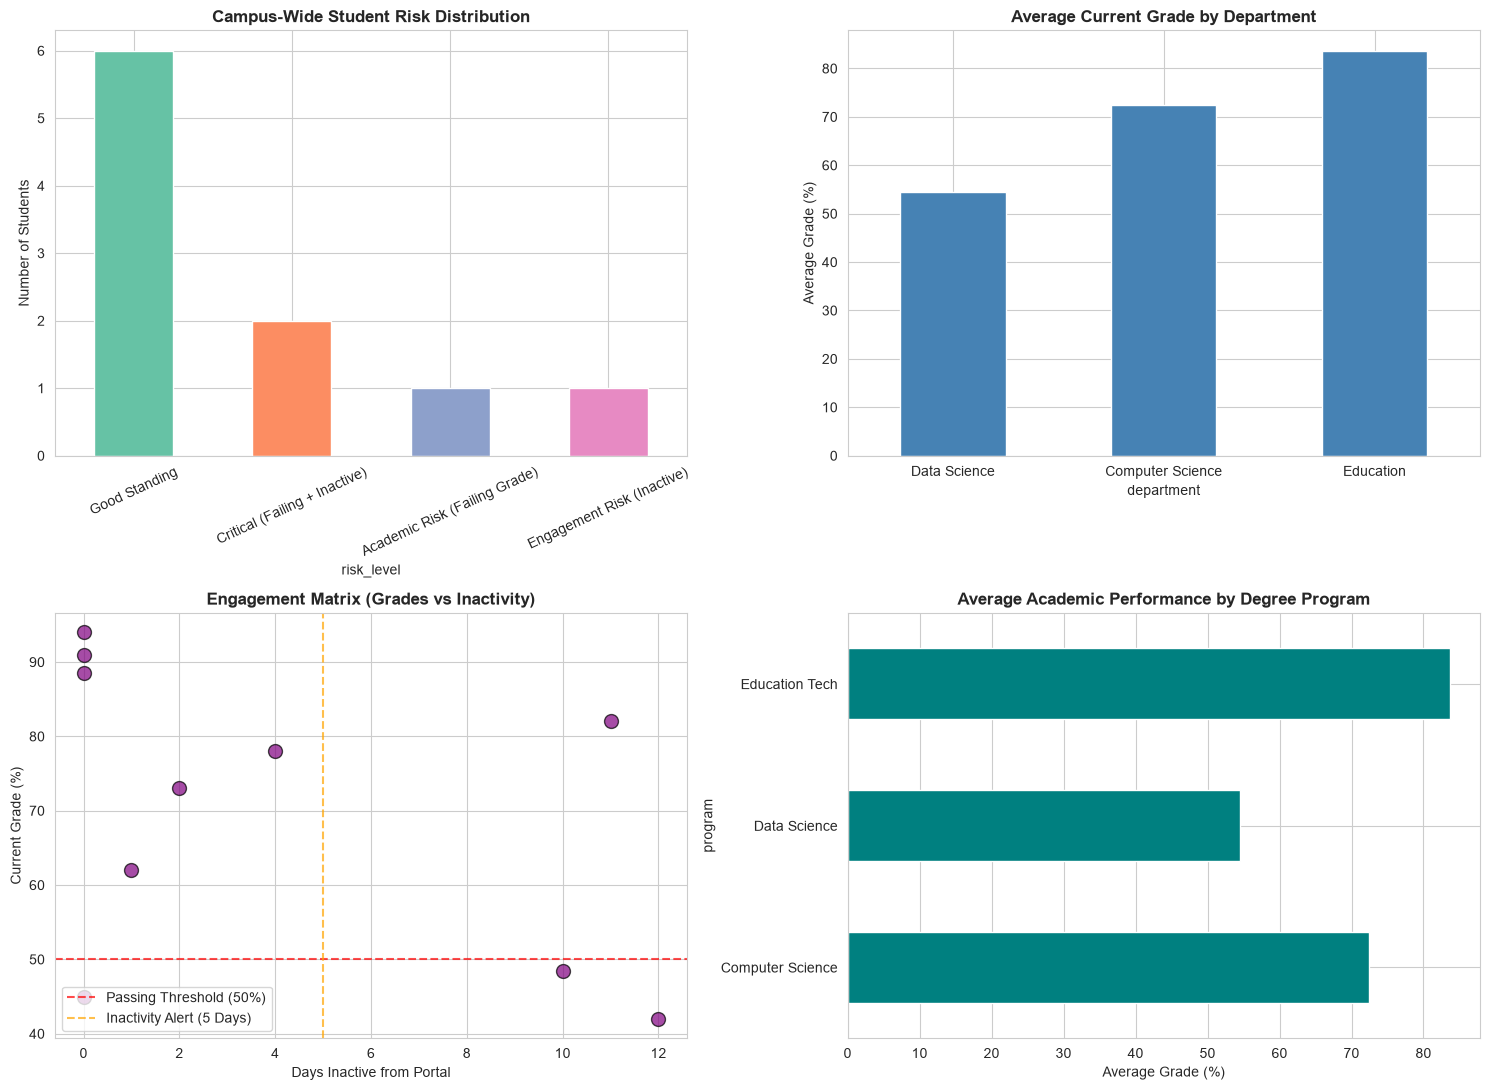

In [9]:
# ==========================================================
# STEP 4: EXECUTIVE ANALYTICAL DASHBOARD
# ==========================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# --- CHART 1: Risk Level Distribution (Top-Left) ---
risk_counts = df_unified['risk_level'].value_counts()
colors = ['green', 'crimson', 'darkorange', 'gold']
risk_counts.plot(kind='bar', ax=axes[0, 0], color=sns.color_palette("Set2"))
axes[0, 0].set_title('Campus-Wide Student Risk Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Students')
axes[0, 0].tick_params(axis='x', rotation=25)

# --- CHART 2: Average Grade by Department (Top-Right) ---
dept_grades = df_unified.groupby('department')['current_grade'].mean().sort_values()
dept_grades.plot(kind='bar', ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Average Current Grade by Department', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Average Grade (%)')
axes[0, 1].tick_params(axis='x', rotation=0)

# --- CHART 3: Engagement Matrix: Grade vs Inactivity (Bottom-Left) ---
axes[1, 0].scatter(df_unified['days_inactive'], df_unified['current_grade'], s=100, color='purple', alpha=0.7, edgecolors='black')
axes[1, 0].axhline(50, color='red', linestyle='--', alpha=0.7, label='Passing Threshold (50%)')
axes[1, 0].axvline(5, color='orange', linestyle='--', alpha=0.7, label='Inactivity Alert (5 Days)')
axes[1, 0].set_title('Engagement Matrix (Grades vs Inactivity)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Days Inactive from Portal')
axes[1, 0].set_ylabel('Current Grade (%)')
axes[1, 0].legend(loc='lower left')

# --- CHART 4: Program Score Comparison (Bottom-Right) ---
program_grades = df_unified.groupby('program')['current_grade'].mean()
program_grades.plot(kind='barh', ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Average Academic Performance by Degree Program', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Average Grade (%)')

plt.tight_layout()
plt.show()

In [10]:
# ==========================================================
# STEP 5: AUTOMATED REPORT DISPATCH
# ==========================================================

today_stamp = datetime.date.today().strftime('%Y-%m-%d')

# 1. Export Actionable Intervention List (Filter out 'Good Standing')
needs_attention = df_unified[df_unified['risk_level'] != '🟢 GOOD STANDING'].sort_values('current_grade')

action_cols = ['student_id', 'full_name', 'email', 'course_name', 'current_grade', 'days_inactive', 'risk_level']
intervention_filename = f"LMS_Intervention_Priority_List_{today_stamp}.csv"

needs_attention[action_cols].to_csv(intervention_filename, index=False)

print(f"🚨 INTERVENTION REPORT EXPORTED: {intervention_filename}")
print(f"Total students flagged for intervention: {len(needs_attention)}")
display(needs_attention[action_cols])

# 2. Export Department KPI Summary
dept_kpi = df_unified.groupby('department').agg(
    total_students=('student_id', 'count'),
    avg_grade=('current_grade', 'mean'),
    min_grade=('current_grade', 'min'),
    max_grade=('current_grade', 'max'),
    avg_days_inactive=('days_inactive', 'mean')
).round(1)

kpi_filename = f"Department_KPI_Summary_{today_stamp}.csv"
dept_kpi.to_csv(kpi_filename)

print(f"\n📊 EXECUTIVE KPI REPORT EXPORTED: {kpi_filename}")
display(dept_kpi)

🚨 INTERVENTION REPORT EXPORTED: LMS_Intervention_Priority_List_2026-10-14.csv
Total students flagged for intervention: 10


,student_id,full_name,email,course_name,current_grade,days_inactive,risk_level
1,STU_102,James Smith,james@school.edu,Database Architectures,42.0,12,Critical (Failing + Inactive)
8,STU_109,Lena Mueller,lena@school.edu,Learning Analytics Systems,45.0,0,Academic Risk (Failing Grade)
4,STU_105,Grace Eze,grace@school.edu,Database Architectures,48.5,10,Critical (Failing + Inactive)
5,STU_106,Omar Hassan,omar@school.edu,Learning Analytics Systems,62.0,1,Good Standing
7,STU_108,Chidi Nwosu,chidi@school.edu,Database Architectures,73.0,2,Good Standing
3,STU_104,David Chen,david@school.edu,Instructional Design Foundations,78.0,4,Good Standing
9,STU_110,Kwame Asante,kwame@school.edu,Instructional Design Foundations,82.0,11,Engagement Risk (Inactive)
0,STU_101,Amina Okafor,amina@school.edu,Learning Analytics Systems,88.5,0,Good Standing
6,STU_107,Sarah Williams,sarah@school.edu,Instructional Design Foundations,91.0,0,Good Standing
2,STU_103,Fatima Bello,fatima@school.edu,Learning Analytics Systems,94.0,0,Good Standing



📊 EXECUTIVE KPI REPORT EXPORTED: Department_KPI_Summary_2026-10-14.csv


,total_students,avg_grade,min_grade,max_grade,avg_days_inactive
department,,,,,
Computer Science,4,72.4,45.0,94.0,0.2
Data Science,3,54.5,42.0,73.0,8.0
Education,3,83.7,78.0,91.0,5.0


In [11]:
# ==========================================================
# STEP 6: AUTOMATED REPO DOCUMENTATION GENERATOR
# ==========================================================

readme_content = """# 🎓 Enterprise LMS Early Warning & Academic Analytics Pipeline

An automated data engineering and analytics pipeline designed for Higher Education institutions to monitor student LMS activity, detect early-stage drop-out risks, and dispatch actionable intervention lists to academic counseling departments.

## 📌 Executive Problem Solved
Traditional gradebooks only capture academic failure after exams are complete. This pipeline combines **academic performance** (grades) with **behavioral engagement** (LMS clickstream timestamps) to flag disengaged and at-risk students weeks before course failure occurs.

## 🛠️ Architecture & Tech Stack
- **Database Layer:** SQLite relational database (Students, Courses, Enrollments, Clickstream Server Logs).
- **Data Engineering:** Python, Pandas (3-way relational SQL Joins, data sanitization, date math).
- **Analytics & Risk Engine:** Multi-factor logic matrix classifying students into 4 distinct risk tiers.
- **Visualization:** Matplotlib, Seaborn (4-panel Executive Dashboard & Engagement Matrix).
- **Automated Dispatch:** Scheduled CSV report generator with dynamic timestamping.

## 📊 4-Tier Risk Classification Matrix
1. **🔴 CRITICAL:** Grade $< 50\%$ AND Inactive $\ge 5$ Days (Immediate Intervention Required).
2. **🟠 ACADEMIC RISK:** Grade $< 50\%$ but actively logging in (Tutoring Support Required).
3. **🟡 ENGAGEMENT RISK:** Passing grade but Inactive $\ge 5$ Days (Retention Check-in Required).
4. **🟢 GOOD STANDING:** Passing grade and active on portal within 48 hours.

---
*Created as Project 2 in my 60-Day Educational Technology Systems & Analytics Mastery Portfolio.*
"""

with open('README_Project_2.md', 'w') as f:
    f.write(readme_content)

print("✅ README_Project_2.md created successfully!")

✅ README_Project_2.md created successfully!
